In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/processed/final_data.csv')

In [2]:
from sklearn.model_selection import train_test_split

user_summary = (
    df.groupby("user_id")["buy"]
    .sum()
    .reset_index(name="user_buy_count")
)


train_users, val_users = train_test_split(
    user_summary["user_id"],
    test_size=0.30,
    random_state=42,
    stratify=user_summary["user_buy_count"]
)

# Recover all rows belonging to each user
train_new = df[
    df["user_id"].isin(train_users)
].copy()

val_new = df[
    df["user_id"].isin(val_users)
].copy()

In [3]:
print("Train:", train_new.shape)
print("Validation:", val_new.shape)

print("Train users:", train_new["user_id"].nunique())
print("Validation users:", val_new["user_id"].nunique())

print(
    "Common users:",
    len(set(train_new["user_id"]) & set(val_new["user_id"]))
)

Train: (21000, 41)
Validation: (9000, 41)
Train users: 4200
Validation users: 1800
Common users: 0


In [4]:
print("Original:")
print(user_summary["user_buy_count"].value_counts(normalize=True).sort_index())

print("\nTraining:")
print(train_new.groupby("user_id")["buy"].sum().value_counts(normalize=True).sort_index())

print("\nValidation:")
print(val_new.groupby("user_id")["buy"].sum().value_counts(normalize=True).sort_index())

Original:
user_buy_count
0    0.151333
1    0.318167
2    0.303667
3    0.161333
4    0.056000
5    0.009500
Name: proportion, dtype: float64

Training:
buy
0    0.151429
1    0.318095
2    0.303571
3    0.161429
4    0.055952
5    0.009524
Name: proportion, dtype: float64

Validation:
buy
0    0.151111
1    0.318333
2    0.303889
3    0.161111
4    0.056111
5    0.009444
Name: proportion, dtype: float64


In [5]:
# I have conserved the distribution of 0 and 1 in train and val as it was in original file 

In [6]:
train_new.columns

Index(['row_id', 'user_id', 'music_app_user_id', 'age', 'education',
       'spending_capacity_band', 'home_city', 'stated_favourite_genre',
       'past_purchase_count', 'first_timer', 'typical_ticket_spend',
       'usual_booking_lead_days', 'concert_id', 'genres', 'venue_city',
       'event_page_visits_7d', 'wishlisted', 'buy', 'activity_status',
       'total_sessions', 'total_track_events', 'artist_play_count',
       'artist_saved_count', 'artist_saved_rate', 'avg_completion_rate',
       'concert_genre_total_plays', 'concert_genre_total_saved',
       'avg_genre_plays', 'max_genre_plays', 'days_since_sale_opened',
       'days_until_concert', 'distance', 'total_cost', 'city_match',
       'has_discount', 'has_music_app', 'is_travel_search', 'fav_genre_match',
       'fav_genre_missing', 'artist_play_share', 'concert_genre_play_share'],
      dtype='str')

In [7]:
X_columns = [
                'age','education','spending_capacity_band', 'home_city',
                'past_purchase_count', 'first_timer', 'typical_ticket_spend',
                'usual_booking_lead_days', 'concert_id',
                'venue_city','event_page_visits_7d', 'wishlisted','activity_status',
                'total_sessions','artist_saved_rate','avg_completion_rate',
                'concert_genre_total_saved','avg_genre_plays','max_genre_plays',
                'artist_play_share', 'concert_genre_play_share',
                'days_since_sale_opened','days_until_concert', 
                'distance', 'total_cost', 'city_match','has_discount', 
                'has_music_app', 'is_travel_search', 'fav_genre_match',
                'fav_genre_missing'
                ]

# Training
X_train = train_new[X_columns].copy()
y_train = train_new["buy"].copy()

# Validation
X_val = val_new[X_columns].copy()
y_val = val_new["buy"].copy()

In [8]:
print(X_train.shape)
print(y_train.shape)

(21000, 31)
(21000,)


In [9]:
X_train.first_timer.sum()

np.int64(5745)

In [10]:
X_train.isna().sum()

age                             0
education                       0
spending_capacity_band          0
home_city                       0
past_purchase_count             0
first_timer                     0
typical_ticket_spend         5745
usual_booking_lead_days      5745
concert_id                      0
venue_city                      0
event_page_visits_7d          613
wishlisted                      0
activity_status              1170
total_sessions               1170
artist_saved_rate            6420
avg_completion_rate          6420
concert_genre_total_saved    1805
avg_genre_plays              1805
max_genre_plays              1805
artist_play_share            2690
concert_genre_play_share     2690
days_since_sale_opened          0
days_until_concert              0
distance                        0
total_cost                      0
city_match                      0
has_discount                    0
has_music_app                   0
is_travel_search                0
fav_genre_matc

In [11]:
X_train["event_page_visits_7d"].describe()

count    20387.000000
mean         0.604405
std          0.797282
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          6.000000
Name: event_page_visits_7d, dtype: float64

## IMPUTATION AND TRANSFORMATION 

In [12]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
import importlib

from src import merging
from src import preprocessing
from src import feature_engineering
importlib.reload(feature_engineering)
from src import imputation
from src import transformation_encoding


test = pd.read_csv('../data/raw/test_df.csv')
# Lets trasnform our test data as well
# 1.Merging
accounts = pd.read_csv('../data/processed/music_accounts.csv')
tracks =pd.read_csv('../data/processed/music_track_events.csv')


test = merging.add_music_concert_features(test,accounts,tracks)
#2. Feature engineering & preprocessing

test = feature_engineering.build_ifeatures(test)


In [13]:
importlib.reload(preprocessing)
test = preprocessing.remove_cols(test)
test = feature_engineering.genre_matching(test)
test = feature_engineering.correct_music_missing_values(test)
test = feature_engineering.music_affinity_features(test)
test = preprocessing.remove_datetime(test)

In [14]:
test.head()

,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,stated_favourite_genre,past_purchase_count,first_timer,...,distance,total_cost,city_match,has_discount,has_music_app,is_travel_search,fav_genre_match,fav_genre_missing,artist_play_share,concert_genre_play_share
0,R3770C503,U3ACC7254,M0DE861B3,46,undergraduate,1,Lyon,folk_country,5,0,...,0.000000,95.100,1,0,1,1,0.0,0,0.108696,0.304348
1,R216C3DE0,U1C2E3AFA,M3B7890DA,47,undergraduate,5,Paris,rnb_soul,3,0,...,391.520187,117.630,0,0,1,0,0.0,0,0.043478,0.369565
2,R315CFF39,U1593B998,M17CA551F,46,undergraduate,3,Lyon,NaN,0,1,...,556.847527,94.995,0,1,1,0,NaN,1,0.000000,0.366667
3,R0CC22A1C,U15FCAF27,M1B1E629F,18,secondary,3,Rennes,classical,2,0,...,442.127211,85.620,0,1,1,0,0.0,0,0.023810,0.119048
4,R30EE7196,U03D69656,M05B8CCEE,63,postgraduate,1,Lyon,alternative,0,1,...,435.686889,123.720,0,0,1,0,1.0,0,0.085714,0.485714


In [15]:
# Functions ran smoothly guys!!
train_cols = set(train_new.columns)
test_cols = set(test.columns)

print("Columns in train but not test:")
print(train_cols - test_cols)

print("\nColumns in test but not train:")
print(test_cols - train_cols)

Columns in train but not test:
{'buy'}

Columns in test but not train:
{'artist_id'}


In [ ]:
# test = test.drop(columns=['artist_id'])

In [17]:
train_cols = set(train_new.columns) - {'buy'}
test_cols = set(test.columns)

print(train_cols - test_cols)
print(test_cols - train_cols)

set()
set()


In [18]:
# Test predictors
X_test = test[X_columns].copy()

print(X_test.shape)
print(X_test.columns.equals(X_train.columns))

(20000, 31)
True


In [19]:
# IMPUTATION 
import importlib
from src import imputation
importlib.reload(imputation)

X_train, X_val, X_test = imputation.imputer(
    X_train,
    X_val,
    X_test
)

In [20]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (21000, 35)
Validation: (9000, 35)
Test: (20000, 35)


In [21]:
from src import transformation_encoding
import importlib
importlib.reload(transformation_encoding)
preprocessor = transformation_encoding.build_preprocessor()
X_train_transformed = preprocessor.fit_transform(X_train)
X_val_transformed = preprocessor.transform(X_val)
X_test_transformed = preprocessor.transform(X_test)

In [22]:
print("Train:", X_train_transformed.shape)
print("Validation:", X_val_transformed.shape)
print("Test:", X_test_transformed.shape)

Train: (21000, 53)
Validation: (9000, 53)
Test: (20000, 53)


In [23]:
print("Training labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

print("\nTraining data valid:",
      np.isfinite(X_train_transformed).all())

print("Validation data valid:",
      np.isfinite(X_val_transformed).all())

Training labels:
buy
0    13940
1     7060
Name: count, dtype: int64

Validation labels:
buy
0    5974
1    3026
Name: count, dtype: int64

Training data valid: True
Validation data valid: True


## Logistic Regression baseline with F1 score 0.7355

In [40]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

print(log_model)

LogisticRegression(max_iter=1000, random_state=42)


In [41]:
log_model.fit(X_train_transformed, y_train)

print("Training completed!")
print("Iterations:", log_model.n_iter_)

Training completed!
Iterations: [42]


In [42]:
y_val_pred = log_model.predict(X_val_transformed)

print("First 20 predictions:")
print(y_val_pred[:20])

First 20 predictions:
[1 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 0 0 1]


In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
print("F1 Score:", f1_score(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

F1 Score: 0.7354771784232366

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.89      0.87      5974
           1       0.77      0.70      0.74      3026

    accuracy                           0.83      9000
   macro avg       0.81      0.80      0.81      9000
weighted avg       0.83      0.83      0.83      9000



## Random Forest Classifier baseline with F1 score 0.7348

In [44]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42
)

print(rf_model)

RandomForestClassifier(random_state=42)


In [45]:
rf_model.fit(X_train_transformed, y_train)

print("Training completed!")

Training completed!


In [46]:
y_val_pred_rf = rf_model.predict(X_val_transformed)

print("First 20 predictions:")
print(y_val_pred_rf[:20])

First 20 predictions:
[1 1 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 0 0 1]


In [48]:
print("F1 Score:", f1_score(y_val, y_val_pred_rf))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf))

F1 Score: 0.732080723729993

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      5974
           1       0.77      0.70      0.73      3026

    accuracy                           0.83      9000
   macro avg       0.81      0.80      0.80      9000
weighted avg       0.83      0.83      0.83      9000



,feature,importance
11,num__artist_play_share,0.158952
6,num__artist_saved_rate,0.140770
7,num__avg_completion_rate,0.062371
2,num__typical_ticket_spend,0.055331
12,num__concert_genre_play_share,0.053179
0,num__age,0.041352
9,num__avg_genre_plays,0.037146
16,num__total_cost,0.035523
3,num__usual_booking_lead_days,0.035497
5,num__total_sessions,0.032623


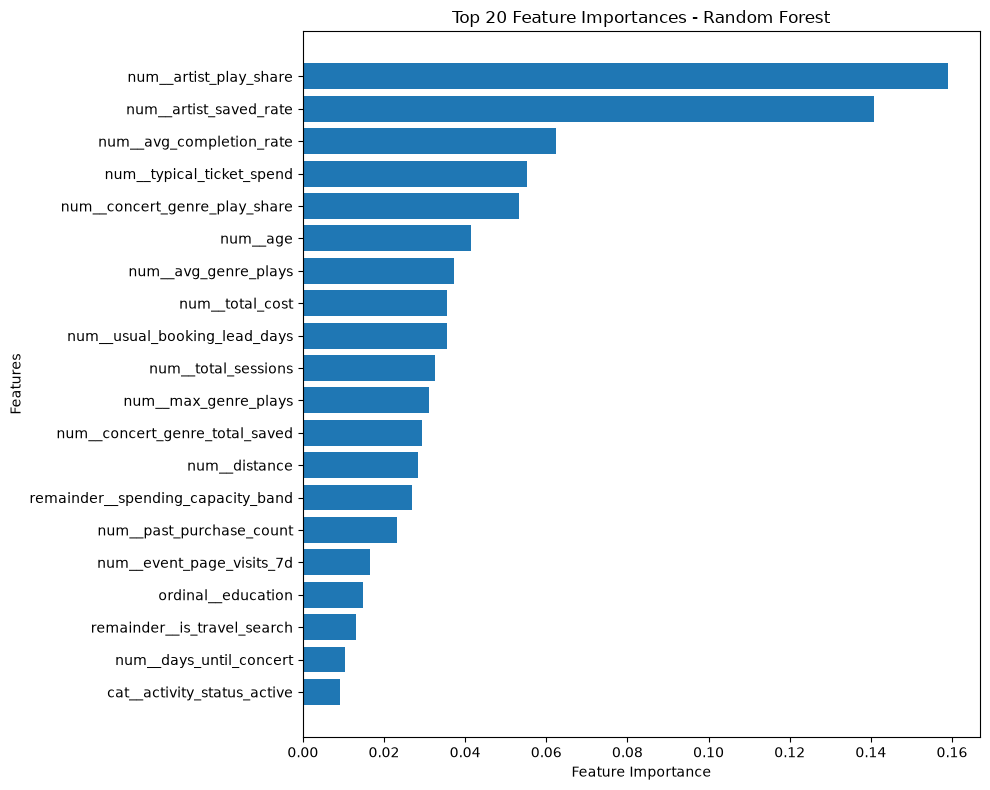

In [49]:
import matplotlib.pyplot as plt

# 1. Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# 2. Calculate feature importance
feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

# 3. Display results
display(feature_importance)

# 4. Plot top 20 important features
top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features['feature'],
    top_features['importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 20 Feature Importances - Random Forest')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Dicision Tree baseline with F1 score 0.6583

In [50]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

print(dt_model)

DecisionTreeClassifier(random_state=42)


In [51]:
dt_model.fit(X_train_transformed, y_train)

print("Training completed!")

Training completed!


In [52]:
y_val_pred_dt = dt_model.predict(X_val_transformed)

print("First 20 predictions:")
print(y_val_pred_dt[:20])

First 20 predictions:
[1 1 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 0 0 1]


In [53]:
print("F1 Score:", f1_score(y_val, y_val_pred_dt))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_dt))

F1 Score: 0.6627623230844314

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.82      0.83      5974
           1       0.65      0.67      0.66      3026

    accuracy                           0.77      9000
   macro avg       0.74      0.75      0.74      9000
weighted avg       0.77      0.77      0.77      9000



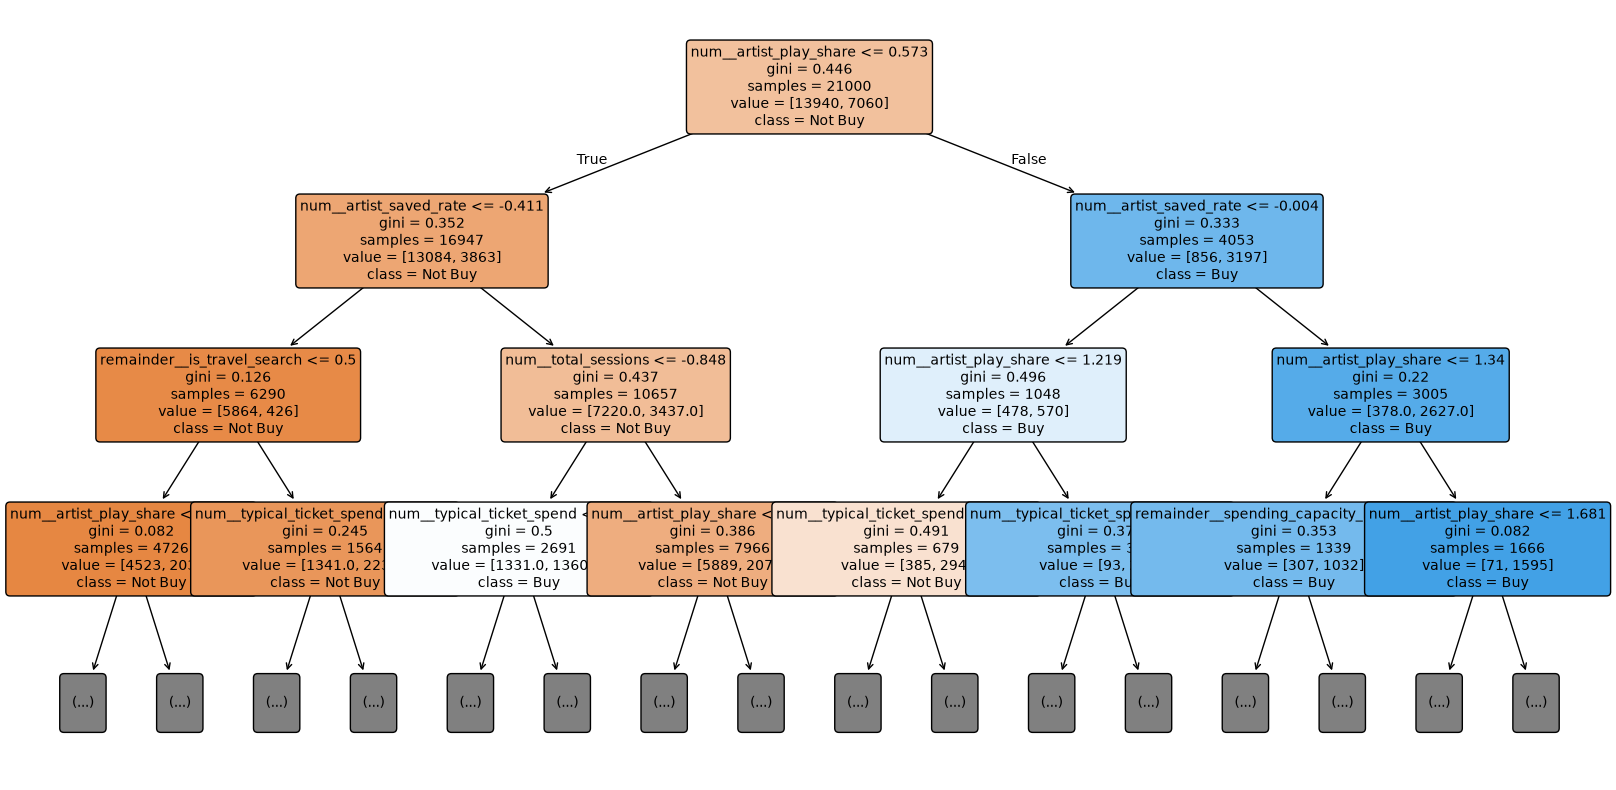

In [54]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=feature_names,
    class_names=['Not Buy', 'Buy'],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

In [60]:
# Trying the XGBoost model
!pip install xgboost

from xgboost import XGBClassifier
xgb = XGBClassifier(objective = 'binary:logistic',eval_metric='logloss',random_state=42)
xgb.fit(X_train_transformed,y_train)
y_pred_xgb = xgb.predict(X_val_transformed)
print(f1_score(y_val,y_pred_xgb))

0.7473273375190904


In [61]:
y_val_prob = xgb.predict_proba(X_val_transformed)[:, 1]

In [62]:
# Optimizing the correct threshold for XGBoost since it h=gave the highest baseline score
thresholds = np.arange(0.1, 0.91, 0.01)

scores = []

for t in thresholds:
    pred = (y_val_prob >= t).astype(int)
    scores.append(f1_score(y_val, pred))

best_idx = np.argmax(scores)

print("Best threshold:", thresholds[best_idx])
print("Best F1:", scores[best_idx])

Best threshold: 0.34999999999999987
Best F1: 0.7585888152826992


In [64]:
# CV and Tuning on the train one 
groups = train_new.loc[X_train.index, "user_id"]
print("Training rows:", len(X_train))
print("Unique users:", groups.nunique())
print("Rows per user:")
print(groups.value_counts().value_counts())

Training rows: 21000
Unique users: 4200
Rows per user:
count
5    4200
Name: count, dtype: int64


In [99]:
from src import optuna
import importlib

importlib.reload(optuna)


study = optuna.tune_xgb(
    X=X_train_transformed,
    y=y_train,
    groups=groups,
    n_trials=80
)

[I 2026-11-18 11:13:57,518] A new study created in memory with name: no-name-f69d3d8a-1859-4bf2-b55d-7c4fe1d69255
[I 2026-11-18 11:14:06,363] Trial 0 finished with value: 0.7357483395251236 and parameters: {'n_estimators': 874, 'max_depth': 7, 'learning_rate': 0.1205712628744377, 'min_child_weight': 6, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'gamma': 0.2904180608409973, 'reg_alpha': 2.142302175774105, 'reg_lambda': 0.10129197956845731}. Best is trial 0 with value: 0.7357483395251236.
[I 2026-11-18 11:14:12,978] Trial 1 finished with value: 0.7272116491186379 and parameters: {'n_estimators': 1475, 'max_depth': 3, 'learning_rate': 0.27081608642499677, 'min_child_weight': 9, 'subsample': 0.6849356442713105, 'colsample_bytree': 0.6727299868828402, 'gamma': 0.9170225492671691, 'reg_alpha': 0.003320559103751959, 'reg_lambda': 0.042051564509138696}. Best is trial 0 with value: 0.7357483395251236.
[I 2026-11-18 11:14:17,821] Trial 2 finished with value: 0.746367

In [100]:
print("Best CV F1:", study.best_value)
print("Best parameters:", study.best_params)

Best CV F1: 0.7537469907173069
Best parameters: {'n_estimators': 1846, 'max_depth': 5, 'learning_rate': 0.2170330082160793, 'min_child_weight': 4, 'subsample': 0.6933771887811736, 'colsample_bytree': 0.9996610318603915, 'gamma': 4.683421146519432, 'reg_alpha': 2.3117730923600885, 'reg_lambda': 8.82865947514511}


In [101]:
from src import model
import importlib
importlib.reload(model)

best_xgb = model.build_xgb_model(study.best_params)

best_xgb.fit(X_train_transformed, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.9996610318603915
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [102]:
y_val_prob = best_xgb.predict_proba(
    X_val_transformed
)[:, 1]

In [103]:
# at default threshold
from sklearn.metrics import f1_score
y_val_pred = (y_val_prob >= 0.5).astype(int)

print("Validation F1:", f1_score(y_val, y_val_pred))

Validation F1: 0.7627780607913058


In [104]:
thresholds = np.arange(0.1, 0.91, 0.01)

scores = []

for t in thresholds:
    pred = (y_val_prob >= t).astype(int)
    scores.append(f1_score(y_val, pred))

best_idx = np.argmax(scores)

best_threshold = thresholds[best_idx]

print("Best threshold:", best_threshold)
print("Best validation F1:", scores[best_idx])

Best threshold: 0.38999999999999985
Best validation F1: 0.7716560012486343


In [105]:
test_prob = best_xgb.predict_proba(
    X_test_transformed
)[:, 1]

In [106]:
best_threshold = 0.39

test_predictions = (
    test_prob >= best_threshold
).astype(int)

In [108]:
submission = pd.DataFrame({
    "row_id": test.loc[X_test.index, "row_id"].values,
    "buy": test_predictions
})

In [109]:
print(submission.head())
print(submission.shape)

print(submission["buy"].value_counts())
print(submission.isna().sum())

      row_id  buy
0  R3770C503    0
1  R216C3DE0    0
2  R315CFF39    0
3  R0CC22A1C    0
4  R30EE7196    1
(20000, 2)
buy
0    12673
1     7327
Name: count, dtype: int64
row_id    0
buy       0
dtype: int64


In [111]:
submission.to_csv(
    "../submissions/submission_v1.csv",
    index=False
)

In [81]:
# Improvement

In [112]:
from sklearn.metrics import f1_score
import pandas as pd

results = val_new[["concert_id", "buy"]].copy()

results["pred"] = y_pred_best

concert_scores = results.groupby("concert_id").apply(
    lambda x: f1_score(x["buy"], x["pred"]),
    include_groups=False
)

print(concert_scores)

concert_id
C01    0.774297
C02    0.758347
C03    0.774194
C04    0.697674
C05    0.777070
dtype: float64


In [85]:
feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": best_xgb.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print(importance.head(20))

                              feature  importance
11             num__artist_play_share    0.142836
50      remainder__music_rate_missing    0.105196
6              num__artist_saved_rate    0.094876
35        cat__activity_status_active    0.090747
5                 num__total_sessions    0.071105
46        remainder__is_travel_search    0.022851
2           num__typical_ticket_spend    0.021197
1            num__past_purchase_count    0.017861
33                cat__concert_id_C04    0.017660
43              remainder__city_match    0.015824
40  remainder__spending_capacity_band    0.015256
4           num__event_page_visits_7d    0.015066
3        num__usual_booking_lead_days    0.014452
15                      num__distance    0.013999
12      num__concert_genre_play_share    0.013724
7            num__avg_completion_rate    0.013593
28             cat__venue_city_Nantes    0.013510
25           cat__venue_city_Bordeaux    0.013203
32                cat__concert_id_C03    0.013053


In [114]:
# Catboostttt

from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, classification_report
cat_cols = [
    "education",
    "home_city",
    "venue_city",
    "concert_id",
    "activity_status"
]
X_train_cat = X_train.copy()
X_val_cat = X_val.copy()

for col in cat_cols:
    X_train_cat[col] = X_train_cat[col].fillna("unknown").astype(str)
    X_val_cat[col] = X_val_cat[col].fillna("unknown").astype(str)

cat_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="F1",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

cat_model.fit(
    X_train_cat,
    y_train,
    cat_features=cat_cols
)
y_val_pred_cat = cat_model.predict(X_val_cat)

print("CatBoost Baseline F1:",
      f1_score(y_val, y_val_pred_cat))

0:	learn: 0.5834386	total: 17.3ms	remaining: 17.3s
100:	learn: 0.7571640	total: 1.32s	remaining: 11.8s
200:	learn: 0.7724037	total: 2.94s	remaining: 11.7s
300:	learn: 0.7848194	total: 5.71s	remaining: 13.3s
400:	learn: 0.7954579	total: 8.09s	remaining: 12.1s
500:	learn: 0.8042569	total: 10.2s	remaining: 10.2s
600:	learn: 0.8130416	total: 12.4s	remaining: 8.24s
700:	learn: 0.8227439	total: 14.7s	remaining: 6.29s
800:	learn: 0.8314887	total: 16.8s	remaining: 4.17s
900:	learn: 0.8406541	total: 19s	remaining: 2.09s
999:	learn: 0.8494356	total: 21s	remaining: 0us
CatBoost Baseline F1: 0.7590669163970714


In [115]:
import numpy as np
from sklearn.metrics import f1_score

y_val_prob_cat = cat_model.predict_proba(X_val_cat)[:, 1]

thresholds = np.arange(0.1, 0.91, 0.01)

scores_cat = []

for t in thresholds:
    pred = (y_val_prob_cat >= t).astype(int)
    scores_cat.append(f1_score(y_val, pred))

best_idx_cat = np.argmax(scores_cat)

best_threshold_cat = thresholds[best_idx_cat]

print("Best threshold:", best_threshold_cat)
print("Best CatBoost F1:", scores_cat[best_idx_cat])

Best threshold: 0.38999999999999985
Best CatBoost F1: 0.7696162881754112


In [116]:
# ensemble
xgb_prob = best_xgb.predict_proba(X_val_transformed)[:, 1]

cat_prob = cat_model.predict_proba(X_val_cat)[:, 1]

# Equal-weight ensemble
ensemble_prob = (xgb_prob + cat_prob) / 2

In [117]:
thresholds = np.arange(0.1, 0.91, 0.01)

ensemble_scores = []

for t in thresholds:
    pred = (ensemble_prob >= t).astype(int)
    ensemble_scores.append(f1_score(y_val, pred))

best_idx = np.argmax(ensemble_scores)

print("Best threshold:", thresholds[best_idx])
print("Ensemble F1:", ensemble_scores[best_idx])

Best threshold: 0.39999999999999986
Ensemble F1: 0.7721399306649858


In [120]:
from src import optuna_cat
import importlib

importlib.reload(optuna_cat)
cat_cols = [
    "education",
    "home_city",
    "venue_city",
    "concert_id",
    "activity_status"
]
groups = train_new.loc[X_train_cat.index, "user_id"]
study_cat = optuna_cat.tune_catboost(
    X=X_train_cat,
    y=y_train,
    groups=groups,
    cat_features=cat_cols,
    n_trials=10
)

[I 2026-11-18 12:24:38,978] A new study created in memory with name: catboost_optimization


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-18 12:32:46,367] Trial 0 finished with value: 0.7331520701980349 and parameters: {'iterations': 874, 'depth': 10, 'learning_rate': 0.29106359131330695, 'l2_leaf_reg': 3.968793330444372, 'random_strength': 0.31203728088487304, 'bagging_temperature': 0.7799726016810132, 'border_count': 45}. Best is trial 0 with value: 0.7331520701980349.
[I 2026-11-18 12:38:53,718] Trial 1 finished with value: 0.7298548912810757 and parameters: {'iterations': 1367, 'depth': 8, 'learning_rate': 0.2607024758370767, 'l2_leaf_reg': 1.0485387725194617, 'random_strength': 1.9398197043239886, 'bagging_temperature': 4.162213204002109, 'border_count': 79}. Best is trial 0 with value: 0.7331520701980349.
[I 2026-11-18 12:40:35,832] Trial 2 finished with value: 0.7533822556456149 and parameters: {'iterations': 682, 'depth': 5, 'learning_rate': 0.04059611610484305, 'l2_leaf_reg': 3.347776308515933, 'random_strength': 0.8638900372842315, 'bagging_temperature': 1.4561457009902097, 'border_count': 169}. Best

In [121]:
print(study_cat.best_value)
print(study_cat.best_params)

0.7533822556456149
{'iterations': 682, 'depth': 5, 'learning_rate': 0.04059611610484305, 'l2_leaf_reg': 3.347776308515933, 'random_strength': 0.8638900372842315, 'bagging_temperature': 1.4561457009902097, 'border_count': 169}


In [122]:
best_cat = CatBoostClassifier(
    **study_cat.best_params,
    loss_function="Logloss",
    eval_metric="Logloss",
    random_seed=42,
    verbose=100,
    allow_writing_files=False,
    cat_features=cat_cols
)

best_cat.fit(X_train_cat, y_train)

0:	learn: 0.6675242	total: 76.1ms	remaining: 51.8s
100:	learn: 0.3657101	total: 3.71s	remaining: 21.4s
200:	learn: 0.3466205	total: 10.2s	remaining: 24.4s
300:	learn: 0.3346855	total: 13.9s	remaining: 17.6s
400:	learn: 0.3267467	total: 17.1s	remaining: 12s
500:	learn: 0.3198519	total: 19.8s	remaining: 7.16s
600:	learn: 0.3131759	total: 21.7s	remaining: 2.92s
681:	learn: 0.3080950	total: 23.1s	remaining: 0us


CatBoostClassifier(allow_writing_files=False, bagging_temperature=1.4561457009902097, border_count=169, cat_features=['education', 'home_city', 'venue_city', 'concert_id', 'activity_status'], depth=5, eval_metric='Logloss', iterations=682, l2_leaf_reg=3.347776308515933, learning_rate=0.04059611610484305, loss_function='Logloss', random_seed=42, random_strength=0.8638900372842315, verbose=100)

In [123]:
y_val_prob_cat = best_cat.predict_proba(X_val_cat)[:, 1]

y_val_pred_cat = (y_val_prob_cat >= 0.5).astype(int)

print("CatBoost Validation F1:",
      f1_score(y_val, y_val_pred_cat))

CatBoost Validation F1: 0.7659935516714746


In [124]:
thresholds = np.arange(0.25, 0.61, 0.01)

scores = []

for threshold in thresholds:
    pred = (y_val_prob_cat >= threshold).astype(int)
    scores.append(f1_score(y_val, pred))

best_idx = np.argmax(scores)

best_threshold_cat = thresholds[best_idx]

print("Best threshold:", best_threshold_cat)
print("Best CatBoost F1:", scores[best_idx])

Best threshold: 0.42000000000000015
Best CatBoost F1: 0.771884984025559


In [126]:
xgb_prob = best_xgb.predict_proba(X_val_transformed)[:, 1]
cat_prob = best_cat.predict_proba(X_val_cat)[:, 1]

ensemble_prob = (
    0.5 * xgb_prob +
    0.5 * cat_prob
)

thresholds = np.arange(0.25, 0.61, 0.01)

scores = []

for threshold in thresholds:
    pred = (ensemble_prob >= threshold).astype(int)
    scores.append(f1_score(y_val, pred))

best_idx = np.argmax(scores)

print("Best ensemble threshold:", thresholds[best_idx])
print("Best ensemble F1:", scores[best_idx])

Best ensemble threshold: 0.44000000000000017
Best ensemble F1: 0.7748097782094868


In [127]:
weights = [0.3, 0.4, 0.5, 0.6, 0.7]

for w in weights:
    ensemble_prob = (
        w * xgb_prob +
        (1 - w) * cat_prob
    )

    best_f1 = 0
    best_threshold = 0

    for threshold in np.arange(0.30, 0.61, 0.01):
        pred = (ensemble_prob >= threshold).astype(int)
        score = f1_score(y_val, pred)

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    print(
        f"XGB weight: {w:.1f} | "
        f"Cat weight: {1-w:.1f} | "
        f"F1: {best_f1:.5f} | "
        f"Threshold: {best_threshold:.2f}"
    )

XGB weight: 0.3 | Cat weight: 0.7 | F1: 0.77545 | Threshold: 0.42
XGB weight: 0.4 | Cat weight: 0.6 | F1: 0.77583 | Threshold: 0.43
XGB weight: 0.5 | Cat weight: 0.5 | F1: 0.77481 | Threshold: 0.44
XGB weight: 0.6 | Cat weight: 0.4 | F1: 0.77453 | Threshold: 0.42
XGB weight: 0.7 | Cat weight: 0.3 | F1: 0.77466 | Threshold: 0.42


In [129]:
final_xgb_weight = 0.4
final_cat_weight = 0.6
final_threshold = 0.43

xgb_test_prob = best_xgb.predict_proba(X_test_transformed)[:, 1]

cat_test_prob = best_cat.predict_proba(X_test)[:, 1]

final_test_prob = (
    final_xgb_weight * xgb_test_prob +
    final_cat_weight * cat_test_prob
)

final_predictions = (
    final_test_prob >= final_threshold
).astype(int)

In [131]:
submission = pd.DataFrame({
    "row_id": test["row_id"].values,
    "buy": final_predictions
})

submission.to_csv(
    "../submissions/submission_v2.csv",
    index=False
)